# Learning the dynamics of PDEs with LDNet (Test Case 1b)

This notebook contains a tutorial with an example of usage of an LDNet to learn the dynamics underlying the following Diffusion-Reaction equation (Test case 1b, Section 3.1.3 of the Supplementary Information):
$$
\begin{cases}
\frac{\partial z(x,t)}{\partial t} - \mu_1 \frac{\partial^2 z(x,t)}{\partial x^2} + \mu_3 z(x,t) = A(t) \cos(\pi x − P(t)), & x \in (-1,1), t\in (0,T], \\
z(-1,t) = z(1,t) & t\in (0,T], \\
z(x,0)= 0 & x \in (-1,1).
\end{cases}
$$
with parameters $\mu_1 = 0.05$ and $\mu_3 = 0.02$. The LDNet is trained in order to predict the space-time dynamics of $z(x,t)$ for a generic input $\mathbf{u}(t) = (A(t), P(t))$.

In [27]:
# import modules
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
# tensorflow-metal has no float64 Adam kernel -> force CPU
tf.config.set_visible_devices([], 'GPU')
# We configure TensorFlow to work in double precision 
tf.keras.backend.set_floatx('float64')

import utils
import optimization

### Problem setting

We define the name of the variables of the problem at hand.

In [28]:
problem = {
    'space': {
        'dimension' : 1
    },
    'input_parameters': [],
    'input_signals': [
        { 'name': 'amplitude' },
        { 'name': 'phase' }
    ],
    'output_fields': [
        { 'name': 'z' }
    ]
}

We define, for each variable, a lower and an upper bound to be used to normalize the data.

In [29]:

#* The input_signals are the u_1(t) and u_2(t) of the forcing term f(x,t) = u₁(t) cos(πx − u₂(t))
normalization = {
    'space': { 'min' : [-1], 'max' : [+1]},
    'time': { 'time_constant' : 2.3 },
    'input_signals': {
        'amplitude': { 'min':   0, 'max': 0.8},
        'phase'    : { 'min':  -4, 'max': 4 },
    },
    'output_fields': {
        'z': { 'min': -1, 'max': +1 }
    }
}

We define the time step size and the number of latent variables used by the LDNet.

In [30]:
dt = 5e-2
num_latent_states = 2

### Datasets

We load training, validation and testing data. Here, training, validation and test sets comprise $n_{\mathrm{samples}} = 100$ samples each.
We resample data points on a regular grid with $n_{\mathrm{times}} = 101$ time instants and $n_{\mathrm{points}} = 100$ space points.
By following the notation of the paper, we denote by $d = 1$ the spatial dimension, by $d_{\mathbf{u}} = 2$ the number of input parameters and by $d_{\mathbf{y}} = 1$ the number of output fields.

Each dataset is stored as a Python dictionary, with the following fields (shape is indicated in square brackets):
- `times` $[n_{\mathrm{times}}]$: time instants;
- `points` $[n_{\mathrm{points}}, d]$: space points;
- `points_full` $[n_{\mathrm{samples}}, n_{\mathrm{times}}, n_{\mathrm{points}}, d]$: space points repeated for each sample and time instant;
- `inp_signals` $[n_{\mathrm{samples}}, n_{\mathrm{times}}, d_{\mathbf{u}}]$: input signals for each sample and time instant;
- `out_fields` $[n_{\mathrm{samples}}, n_{\mathrm{times}}, n_{\mathrm{points}}, d_{\mathbf{y}}]$: output fields for each sample, time instant and space point.

In [31]:
data_set_path = '../data/ADR/data_1b.npy'
samples_train = np.arange(  0, 100)
samples_valid = np.arange(100, 200)
samples_tests = np.arange(200, 300)

dataset = np.load(data_set_path, allow_pickle = True)[()]
dataset_train = utils.ADR_create_dataset(dataset, samples_train)
dataset_valid = utils.ADR_create_dataset(dataset, samples_valid) 
dataset_tests = utils.ADR_create_dataset(dataset, samples_tests) 

# We re-sample the time transients with timestep dt and we rescale each variable between -1 and 1.
utils.process_dataset(dataset_train, problem, normalization, dt = dt)
utils.process_dataset(dataset_valid, problem, normalization, dt = dt)
utils.process_dataset(dataset_tests, problem, normalization, dt = dt)

### Architecture

We create two fully-connected neural networks of which the LDNet is made up:
- the dynamics network $\mathcal{NN}_{\mathrm{dyn}}$, with two hidden layers of 10 neurons each;
- the reconstruction network $\mathcal{NN}_{\mathrm{rec}}$, with two hidden layers of 7 neurons each.

**NNdyn**

Called **inside the time loop**, once per time step. At time step `i` you hand it:

| Part | Shape | Meaning |
|------|-------|---------|
| `state` | (100, 2) | 100 samples × 2 latent numbers |
| `inp_signals[:, i, :]` | (100, 2) | 100 samples × 2 signal numbers (amplitude, phase at time `i`) |
| concatenated → **input** | **(100, 4)** | — |
| **output** | **(100, 2)** | the change (derivative) for the 100 samples |

So NNdyn always sees a **2-D table: 100 rows (samples) × 4 numbers**.
It never sees time or space as a dimension — you feed it one time slice at a time.
It runs 100 times (once per step) to build the whole trajectory.


Model: "sequential_3"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 dense_9 (Dense)             (None, 10)                50        
                                                                 
 dense_10 (Dense)            (None, 10)                110       
                                                                 
 dense_11 (Dense)            (None, 2)                 22        
                                                                 
Total params: 182
Trainable params: 182
Non-trainable params: 0
_________________________________________________________________


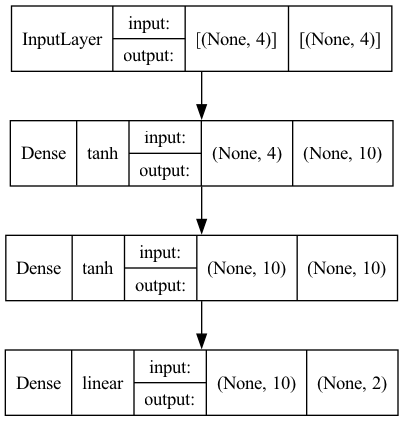

In [32]:
# For reproducibility (delete if you want to test other random initializations)
np.random.seed(0)
tf.random.set_seed(0)

# dynamics network
#* (batch,4) @ (4,10) → (batch,10) @ (10,10) → (batch,10) @ (10,2) → (batch,2)
input_shape = (num_latent_states + len(problem['input_parameters']) + len(problem['input_signals']),)
NNdyn = tf.keras.Sequential([
            tf.keras.layers.Dense(10, activation = tf.nn.tanh, input_shape = input_shape),
            tf.keras.layers.Dense(10, activation = tf.nn.tanh),
            tf.keras.layers.Dense(num_latent_states)
        ])

# summary
NNdyn.summary()

# visualization
tf.keras.utils.plot_model(NNdyn, show_shapes=True, show_layer_names=False, show_layer_activations=True)

**NNrec**

Called **once**, after the trajectory is built. You hand it the whole thing at once:

| Part | Shape | Meaning |
|------|-------|---------|
| `states_expanded` | (100, 101, 100, 2) | 100 samples × 101 times × 100 points × 2 latent numbers |
| `points_full` | (100, 101, 100, 1) | same grid, but the 1 number is the x-coordinate |
| concatenated → **input** | **(100, 101, 100, 3)** | — |
| **output** | **(100, 101, 100, 1)** | the field `z` at every sample/time/point |

So NNrec sees a **4-D block**: 3 indices to locate a cell (which sample, which time, which point) and 3 numbers inside that cell `(s₁, s₂, x)`.
It produces 1 number `z` per cell.

Model: "sequential_4"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 dense_12 (Dense)            (None, None, None, 7)     28        
                                                                 
 dense_13 (Dense)            (None, None, None, 7)     56        
                                                                 
 dense_14 (Dense)            (None, None, None, 1)     8         
                                                                 
Total params: 92
Trainable params: 92
Non-trainable params: 0
_________________________________________________________________


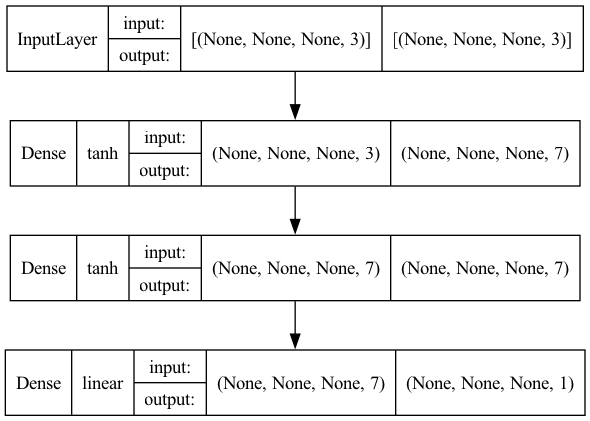

In [33]:
# reconstruction network
#* input_shape = (times, points, num_latent_states + dimension) → (times, points, 7) → (times, points, 7) → (times, points, output_fields)
input_shape = (None, None, num_latent_states + problem['space']['dimension'])
NNrec = tf.keras.Sequential([
            tf.keras.layers.Dense(7, activation = tf.nn.tanh, input_shape = input_shape),
            tf.keras.layers.Dense(7, activation = tf.nn.tanh),
            tf.keras.layers.Dense(len(problem['output_fields']))
        ])

# summary
NNrec.summary()

# visualization
tf.keras.utils.plot_model(NNrec, show_shapes=True, show_layer_names=False, show_layer_activations=True)

The LDNet action is defined through the following two functions:
- `evolve_dynamics` computes the evolution of the latent states;
- `reconstruct_output` reconstructs the output field from the latent states evolution.

In [34]:
dataset_train['num_times'], dataset_train['num_points'], dataset_train['num_samples'], dataset_train['inp_signals'].shape

(201, 100, 100, TensorShape([100, 201, 2]))

In [35]:
def evolve_dynamics(dataset):
    # intial condition
    state = tf.zeros((dataset['num_samples'], num_latent_states), dtype=tf.float64)
    state_history = tf.TensorArray(tf.float64, size = dataset['num_times'])
    state_history = state_history.write(0, state) #* at position 0 save the array state (batch, num_latent_states) of the initial condition
    dt_ref = normalization['time']['time_constant']
    
    # time integration
    for i in tf.range(dataset['num_times'] - 1):
        state = state + dt/dt_ref * NNdyn(tf.concat([state, dataset['inp_signals'][:,i,:]], axis = -1)) #* evolve the state one step for all samples in the batch using s(t) and u(t)
        state_history = state_history.write(i + 1, state)

    return tf.transpose(state_history.stack(), perm=(1,0,2))

def reconstruct_output(dataset, states):    
    #* states has shape (batch, times, num_latent_states)
    states_expanded = tf.broadcast_to(tf.expand_dims(states, axis = 2), 
        [dataset['num_samples'], dataset['num_times'], dataset['num_points'], num_latent_states])
    return NNrec(tf.concat([states_expanded, dataset['points_full']], axis = 3)) #* reconstruct the output field for all samples in the batch using s(t) and x with shape (batch, times, points, output_fields)

def LDNet(dataset):
    states = evolve_dynamics(dataset)
    return reconstruct_output(dataset, states)

### Loss function

We define the loss function as the MSE (mean square error) over the whole dataset plus a Tikhonov regularization on the NNs' weights.

In [36]:
dataset_train["inp_signals"].shape #* shape (batch, times, input_signals)
dataset_train["out_fields"].shape, dataset_train["inp_signals"].shape, dataset_train["points_full"].shape

(TensorShape([100, 201, 100, 1]),
 TensorShape([100, 201, 2]),
 (100, 201, 100, 1))

In [37]:
def MSE(dataset):
    out_fields = LDNet(dataset)
    error = out_fields - dataset['out_fields'] #* The error has shape (batch, times, points, output_fields) so it is calculated for all samples in the batch, for all times, for all points and for all output fields
    return tf.reduce_mean(tf.square(error))

def weights_reg(NN):
    return sum([tf.reduce_mean(tf.square(lay.kernel)) for lay in NN.layers])/len(NN.layers) #* L2 regularization term for the weights of the neural network, averaged over all layers

#* PDE residual for TestCase 1b in physical units: r = dz/dt - mu1*d2z/dx2 + mu3*z - f
mu1 = tf.constant(0.05, dtype=tf.float64)
mu3 = tf.constant(0.02, dtype=tf.float64)
dt_phys = tf.constant(float((dataset_train['times'][1] - dataset_train['times'][0]) * normalization['time']['time_constant']), dtype=tf.float64)

def pde_residual(dataset, states):
    S, T, P = dataset['num_samples'], dataset['num_times'], dataset['num_points']
    x_in = tf.convert_to_tensor(dataset['points_full'], dtype=tf.float64)
    states_exp = tf.broadcast_to(tf.expand_dims(states, axis=2), [S, T, P, num_latent_states])
    with tf.GradientTape() as t2: #* outer tape: d2z/dx2 (exact: NNrec is pointwise in x, so grad-of-sum gives per-cell derivatives)
        t2.watch(x_in)
        with tf.GradientTape() as t1: #* inner tape: dz/dx
            t1.watch(x_in)
            z_pred = NNrec(tf.concat([states_exp, x_in], axis=3))  #* (100,201,100,1): (s₁,s₂,x) → z per cell
        dz_dx = t1.gradient(z_pred, x_in)
    d2z_dx2 = t2.gradient(dz_dx, x_in)
    dz_dt = (z_pred[:, 2:, :, :] - z_pred[:, :-2, :, :]) / (2.0 * dt_phys) #* central FD in time on interior steps
    u = dataset['inp_signals'] #* still normalized: denormalize A in [0,0.8], P in [-4,4]
    A = (0.4 * (u[:, 1:-1, 0:1] + 1.0))[:, :, None, :] #* Don't consider the T-1 because the derivative in time is central derivative on interior steps
    Ph = (4.0 * u[:, 1:-1, 1:2])[:, :, None, :]
    f = A * tf.cos(np.pi * x_in[:, 1:-1, :, :] - Ph)
    r = dz_dt - mu1 * d2z_dx2[:, 1:-1, :, :] + mu3 * z_pred[:, 1:-1, :, :] - f
    return tf.reduce_mean(tf.square(r))

def R_pde(dataset):
    return pde_residual(dataset, evolve_dynamics(dataset))

lambda_pde = 1e-1
alpha_reg = 1e-5
def loss(): return MSE(dataset_train) + lambda_pde * R_pde(dataset_train) + alpha_reg * (weights_reg(NNdyn) + weights_reg(NNrec))
def MSE_valid(): return MSE(dataset_valid)

### LDNet training

We train the LDNet with $50$ iterations based on the Adam optimizer, followed by $150$ iterations based on the BFGS optimizer.
Notice that the trainable variables of the LDNet are given as the union of the trainable variables of $\mathcal{NN}_{\mathrm{dyn}}$ and $\mathcal{NN}_{\mathrm{rec}}$.

In [38]:
trainable_variables = NNdyn.variables + NNrec.variables
opt = optimization.OptimizationProblem(trainable_variables, loss, MSE_valid)

num_epochs_Adam = 50
num_epochs_BFGS = 150

print('training (Adam)...')
opt.optimize_keras(num_epochs_Adam, tf.keras.optimizers.Adam(learning_rate=1e-2))
print('training (BFGS)...')
opt.optimize_BFGS(num_epochs_BFGS)

Tracing functions with autograph...
Tracing completed.
epoch    0   -   training loss: 2.974e-01   -   validation loss 2.790e-01
training (Adam)...
epoch   10   -   training loss: 1.315e-01   -   validation loss 1.189e-01
epoch   20   -   training loss: 1.199e-01   -   validation loss 1.089e-01
epoch   30   -   training loss: 1.080e-01   -   validation loss 9.711e-02
epoch   40   -   training loss: 9.256e-02   -   validation loss 8.392e-02
epoch   50   -   training loss: 7.028e-02   -   validation loss 6.625e-02
training (BFGS)...
epoch   60   -   training loss: 3.422e-02   -   validation loss 3.364e-02
epoch   70   -   training loss: 2.477e-02   -   validation loss 2.580e-02
epoch   80   -   training loss: 2.222e-02   -   validation loss 2.284e-02
epoch   90   -   training loss: 1.998e-02   -   validation loss 2.017e-02
epoch  100   -   training loss: 1.711e-02   -   validation loss 1.819e-02
epoch  110   -   training loss: 1.334e-02   -   validation loss 1.355e-02
epoch  120   -   tr

We plot the progress of training and validation MSE during the advancement of epochs.

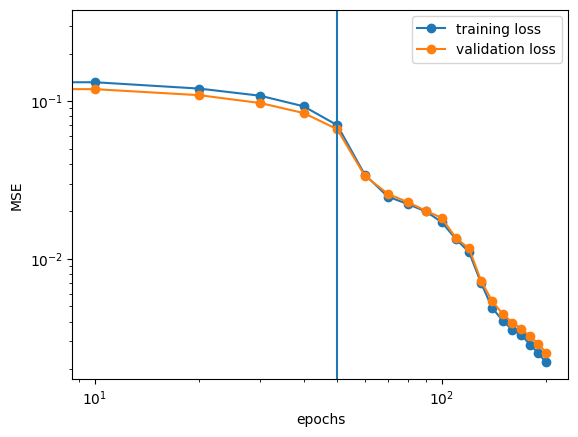

In [39]:
plt.loglog(opt.iterations_history, opt.loss_train_history, 'o-', label = 'training loss')
plt.loglog(opt.iterations_history, opt.loss_valid_history, 'o-', label = 'validation loss')
plt.axvline(num_epochs_Adam)
plt.xlabel('epochs'), plt.ylabel('MSE')
plt.legend()

### Testing

We predict the output field on the testing samples, and we compute error metrics: the normalized root mean square error and the Pearson dissimilarity.

In [40]:
dataset_tests['num_times'], dataset_tests['num_points'], dataset_tests['num_samples'], dataset_tests['inp_signals'].shape

(201, 100, 100, TensorShape([100, 201, 2]))

In [41]:
# Compute predictions.
out_fields = LDNet(dataset_tests)

# Since the LDNet works with normalized data, we map back the outputs into the original ranges.
out_fields_app = utils.denormalize_output(out_fields, problem, normalization).numpy()
out_fields_ref = utils.denormalize_output(dataset_tests['out_fields'], problem, normalization).numpy()

NRMSE = np.sqrt(np.mean(np.square(out_fields_app - out_fields_ref))) / (np.max(out_fields_ref) - np.min(out_fields_ref))

import scipy.stats
R_coeff = scipy.stats.pearsonr(np.reshape(out_fields_app, (-1,)), np.reshape(out_fields_ref, (-1,)))

print('Normalized RMSE:       %1.3e' % NRMSE)
print('Pearson dissimilarity: %1.3e' % (1 - R_coeff[0]))

Normalized RMSE:       2.272e-02
Pearson dissimilarity: 9.101e-03


Finally, we show a comparison between 24 samples from the test set and their correspondent LDNet approximation.

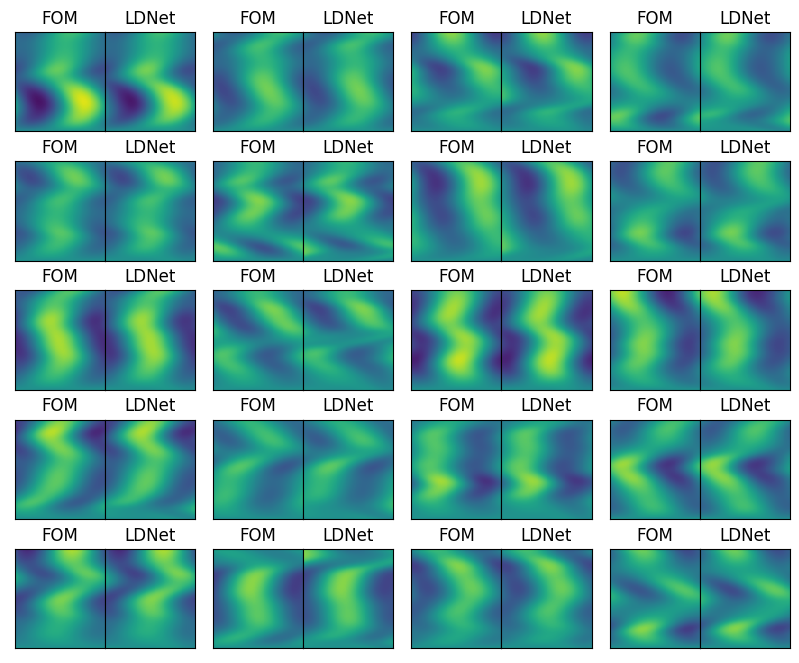

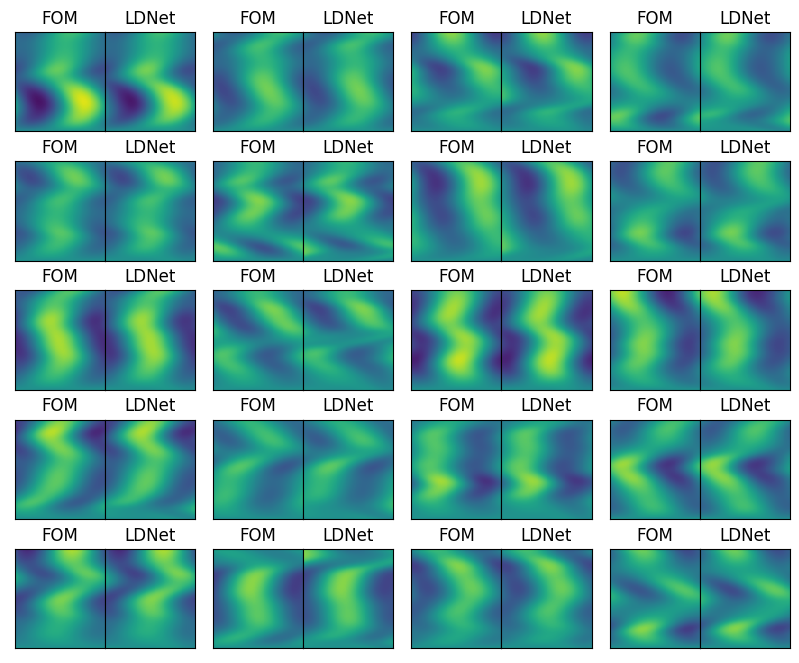

In [42]:
utils.plot_output_1D(dataset_tests, out_fields_ref, out_fields_app, 5, 4, title_ROM = 'LDNet')

### Latent space vs Fourier coefficients (Fig. 2e replica)

Paper Sec. Test Case 1b / Suppl. Fig. 2: at any time $t$, $z(\cdot,t)$ is a sine wave of frequency $0.5$, fully described by $\hat z(0.5)$. We scatter the LDNet latent trajectories $(s_1(t), s_2(t))$ on the test set and color each point by the FOM $\mathrm{Re}(\hat z(0.5))$ (top) and $\mathrm{Im}(\hat z(0.5))$ (bottom). $\hat z$ is the raw `np.fft.fft` along $x$ (100 periodic points, bin 1 = $0.5$ Hz), so values are $O(10)$ — hence the $\pm 40$ colorbar in the paper, not the $O(1)$ $\hat z/N$ scaling.

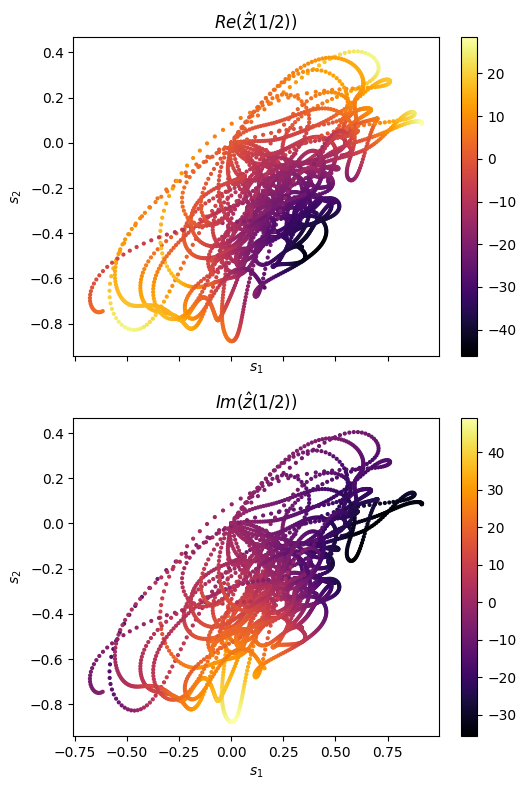

In [43]:
#* Fig. 2e replica: (s1,s2) trajectories colored by FOM Fourier coeff at frequency 0.5
states_test = evolve_dynamics(dataset_tests).numpy()  #* (S,T,2)
z_ref = utils.denormalize_output(dataset_tests['out_fields'], problem, normalization).numpy()[..., 0]  #* (S,T,P) physical
Zhat = np.fft.fft(z_ref, axis=2)  #* periodic grid (endpoint excluded): bin 1 == 0.5 Hz
Re_hat, Im_hat = Zhat[:, :, 1].real, Zhat[:, :, 1].imag

n_plot = min(24, dataset_tests['num_samples'])
# n_plot = dataset_tests['num_samples']
s1 = states_test[:n_plot, :, 0].reshape(-1)
s2 = states_test[:n_plot, :, 1].reshape(-1)
c_re = Re_hat[:n_plot].reshape(-1) #* 24 samples × 201 times
c_im = Im_hat[:n_plot].reshape(-1)

fig, axs = plt.subplots(2, 1, figsize=(5.5, 8), sharex=True, sharey=True)
sc0 = axs[0].scatter(s1, s2, c=c_re, s=4, cmap='inferno')
sc1 = axs[1].scatter(s1, s2, c=c_im, s=4, cmap='inferno')
axs[0].set_title(r'$Re(\hat{z}(1/2))$')
axs[1].set_title(r'$Im(\hat{z}(1/2))$')
for ax in axs:
    ax.set_xlabel(r'$s_1$')
    ax.set_ylabel(r'$s_2$')
fig.colorbar(sc0, ax=axs[0])
fig.colorbar(sc1, ax=axs[1])
plt.tight_layout()
